# Image Processing: Assignment #1
## Submission date: 10/11/2026, 23:59.
### Topics:
- Image Acquisition
- Image Histograms
- Point Operations


**Submitted by:**

- **Student 1 - Ron Benjano, 208980532**
- **Student 2 - Name, ID**


### Assignment Instructions

- Submissions must be completed **in pairs only**. Include both students' full names and ID numbers at the top of the notebook.

- Keep your code **clean, concise, and readable**.

- You may work in your preferred IDE, but you **must** paste your final code into the **corresponding notebook cells** and run it there.

- **Write all textual answers in red** (e.g., using `<span style="color:red">your answer here</span>`).

- All figures, printed results, and other outputs must remain visible in the notebook. **Run all cells** before submitting, and **do not clear the outputs**.

- Use **relative file paths only**. Do not include absolute paths specific to your local machine.

**Important:** The use of ChatGPT and other AI tools is permitted. However, your solutions must rely **only on methods and concepts covered in the course**, and you must **fully understand and be able to explain every part of your submission**. You are responsible for the correctness and originality of your work. Plagiarism or violations of this policy may result in **a grade of zero and disciplinary action**.

Run the setup cell below before starting the assignment.  
It will import all required libraries, load the dataset, and define helper functions used in later cells.


In [26]:
# -- Setup --

# Importing Libraries
import os, re
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
import math, zipfile

try:
    from google.colab import files
except ImportError:
    files = None  # For running the notebook locally

plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['image.cmap'] = 'gray'


def _ensure_data_root():
    """Locate Data/ or extract Data.zip (supports Colab and local notebooks)."""
    for folder in ("/content/Data", "./Data"):
        if os.path.isdir(folder):
            return os.path.abspath(folder)

    for archive, location in (("/content/Data.zip", "/content"),
                              ("./Data.zip", ".")):
        if os.path.isfile(archive):
            with zipfile.ZipFile(archive, 'r') as z:
                z.extractall(location)
            folder = os.path.join(location, 'Data')
            if os.path.isdir(folder):
                return os.path.abspath(folder)

    if files is not None:
        print("Please upload Data.zip")
        uploaded = files.upload()
        assert 'Data.zip' in uploaded, "Please upload a file named Data.zip"
        return _ensure_data_root()

    raise FileNotFoundError("Place the supplied Data.zip next to this notebook and rerun.")


DATA_ROOT = _ensure_data_root()
data_root_q1 = os.path.join(DATA_ROOT, "Q1")
data_root_q2 = os.path.join(DATA_ROOT, "Q2")

# --- Helper functions ---

def imread_gray(path):
    """Read an image as uint8 grayscale, raise an error if missing."""
    img = cv.imread(str(path), cv.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return img


def show_side_by_side(a, b, ta="A", tb="B", cmap='gray'):
    """Show two images side-by-side for quick comparison."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(a, cmap=cmap); axes[0].set_title(ta); axes[0].axis('off')
    axes[1].imshow(b, cmap=cmap); axes[1].set_title(tb); axes[1].axis('off')
    plt.tight_layout(); plt.show()


images_q1 = {
    'flowers': imread_gray(os.path.join(data_root_q1, 'flowers.png')),
    'xray': imread_gray(os.path.join(data_root_q1, 'Xray.png')),
    'building': imread_gray(os.path.join(data_root_q1, 'building.png')),
}

print("Dataset loaded successfully:", DATA_ROOT)

Dataset loaded successfully: /Users/rbenjano/Desktop/Study/ImageProcessing/IP-HW1/Data


## Question 1 - Histograms, Contrast, and Focus (40 Points)

In this question we will explore what we can learn from an image's histogram, and how we can use histograms to change its appearance. We will start by calculating histogram statistics, continue with contrast enhancement and histogram matching, and finally examine whether histograms can help us measure image focus.

You will use the functions you implement in the first sections throughout the question.


### Histogram Statistics

As we learned in class, a histogram counts how many pixels have each gray level. By dividing these counts by the total number of pixels, we obtain the **normalized histogram**, $P(k)$, which gives the probability of observing intensity $k$.

We can use it to describe an image using a few simple statistics:

- **Mean** - the average image intensity (how bright or dark the image is overall).
- **Standard deviation** - how spread out the intensity values are.
- **Entropy** - the uncertainty or information content in the distribution of gray levels.

As we learned in class, entropy is calculated from the normalized histogram:

$$
\mathrm{Entropy}(I) = -\sum_{k:P(k)>0} P(k)\log_2 P(k)
$$


We will also calculate the **Cumulative Distribution Function (CDF)**, which adds up the histogram probabilities up to each gray level. We will need it in the next sections.

In the next cell, implement the following functions:

**`histogram(img)`** - returns an array of 256 intensity counts.

**`hist_stats(img)`** - returns the histogram, normalized CDF, mean, standard deviation, and entropy (in this order).

Calculate the statistics **from the histogram**. You may use `np.bincount` and `np.cumsum`, but not `np.mean`, `np.std`, or a built-in entropy function. Ignore bins with zero probability when calculating entropy.


In [27]:
def histogram(img: np.ndarray) -> np.ndarray:
    """Return an array of 256 intensity counts for a uint8 grayscale image."""
    hist = np.zeros(256, dtype=np.int32)
    for i in range(img.shape[0]): #rows
        for j in range(img.shape[1]): #columns
            hist[img[i, j]] += 1
    return hist

def hist_stats(img: np.ndarray):
    """Return (hist, cdf, mean, std, entropy) computed from the histogram."""
    hist = histogram(img)
    # Compute probability histogram
    prob_hist = hist / np.sum(hist)

    cdf = np.cumsum(prob_hist)
    mean = np.sum(np.arange(256) * prob_hist) 
    std = np.sqrt(np.sum((np.arange(256) - mean) ** 2 * prob_hist))
    entropy = -np.sum(prob_hist[prob_hist > 0] * np.log2(prob_hist[prob_hist > 0]))
    return hist, cdf, mean, std, entropy


Now, let's test your implementation on the three images from the dataset.

Run the next cell to display the images and their histograms, and print the mean, standard deviation, and entropy of each one. The cell will also check that the histogram contains the correct number of pixels and that the final CDF value is 1.


flowers    mean= 124.40  std=  45.56  entropy= 7.037


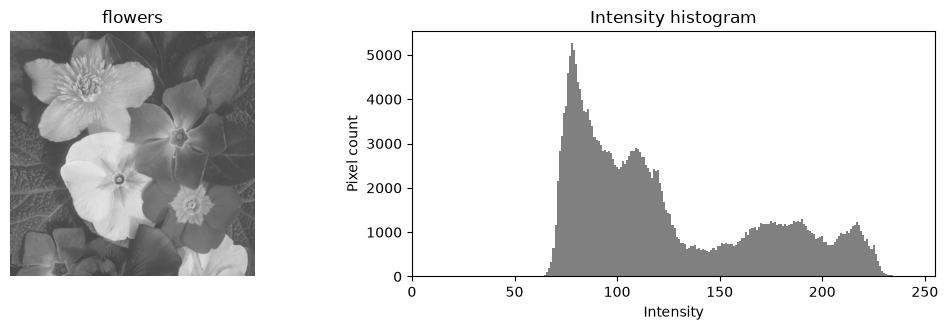

xray       mean= 189.40  std=  74.59  entropy= 6.305


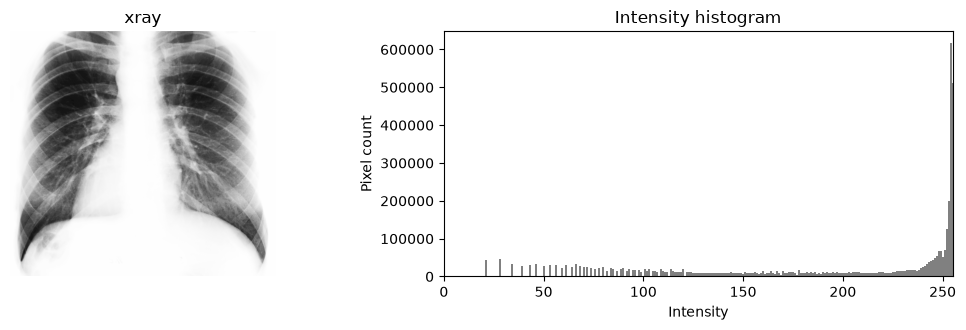

building   mean= 167.60  std=  78.38  entropy= 7.364


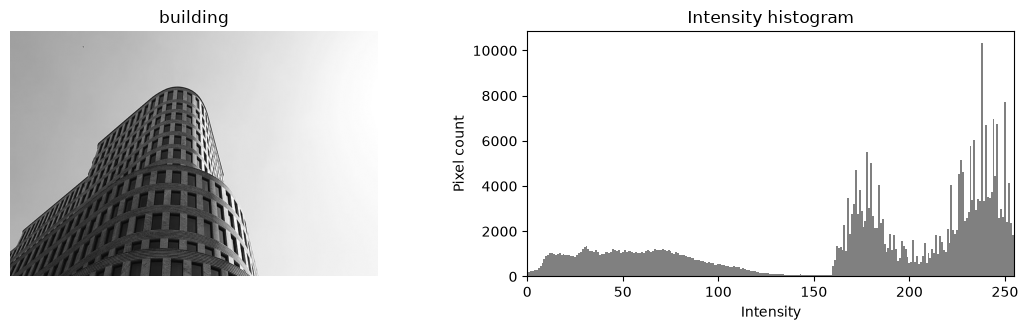

In [28]:
for name, img in images_q1.items():
    hist, F, mu, sigma, H = hist_stats(img)
    assert int(hist.sum()) == img.size
    assert np.isclose(F[-1], 1.0)
    print(f"{name:9s}  mean={mu:7.2f}  std={sigma:7.2f}  entropy={H:6.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(name); axes[0].axis('off')
    axes[1].bar(np.arange(256), hist, width=1, color='gray')
    axes[1].set(xlim=(0,255), xlabel='Intensity', ylabel='Pixel count',
                title='Intensity histogram')
    plt.tight_layout(); plt.show()

<font color='red'><b>Answer the following questions:</b>

1. Which image has the highest entropy? Does this necessarily mean it has the best visual quality? Explain using the images and their histograms.


2. If we shuffle the pixels of an image to different locations, would its mean, standard deviation, or entropy change? Would the histogram still look the same? What does this tell us about histograms?

</font>

<span style="color:red">
ANSWERS

1. The building image has the highest entropy.

   No, histogram entropy specifies the uncertainty in the image's pixel values.

   The X-ray image has the lowest entropy, as most of its pixels are white, which reduces the uncertainty in the pixel values.

   However, the building and flower images have similar histogram entropies, as their histograms are more evenly distributed, making the pixel values less predictable.

2. Histograms are spatially ignorant, meaning shuffling the pixels doesn't affect the histogram, as the count of each pixel value remains the same.

   The mean, standard deviation, and entropy will remain the same, as we calculate them from the histogram.

</span>


### Histogram Shaping

In this section, we will use the histogram to improve image contrast. If most pixel values occupy a small part of the intensity range, we can stretch them to use more of the available gray levels.

Instead of using the minimum and maximum intensities, we will use **percentiles** to avoid letting a few very dark or bright pixels control the entire mapping.

In the next cell, implement `percentile_stretch`:

- Use the CDF to find the intensity levels corresponding to the given lower and upper percentiles.
- Build a **lookup table (LUT)** that maps the lower level to 0 and the upper level to 255, with a linear mapping between them. Values outside the range should be clipped.
- Apply the LUT to the image and return the transformed image, the LUT, and the two chosen intensity levels.

Use `np.rint` to round the values. If the two levels are equal, leave the image unchanged and return the identity LUT. Do not use a built-in contrast stretching function.


In [29]:
def percentile_stretch(img: np.ndarray, low_pct: float = 5, high_pct: float = 95):
    """Return (stretched_image, uint8_LUT, (low_level, high_level))."""
    if not (0 <= low_pct < high_pct <= 100):
        raise ValueError("Require 0 <= low_pct < high_pct <= 100")

    # TODO: use the CDF you already implemented to select the two levels
    _, cdf, _, _, _ = hist_stats(img)
    low_level = np.searchsorted(cdf, low_pct / 100)
    high_level = np.searchsorted(cdf, high_pct / 100)

    if low_level == high_level:
        return img.copy(), np.arange(256, dtype=np.uint8), (low_level, high_level)

    # TODO: construct and apply a 256-entry monotone LUT
    lut = np.zeros(256, dtype=np.uint8)
    values = np.linspace(0, 255, high_level - low_level + 1)
    lut[low_level:high_level + 1] = np.rint(values).astype(np.uint8)
    lut[high_level + 1:] = 255 #clip everything above high_level to 255
    stretched_image = lut[img]
    
    return stretched_image, lut, (low_level, high_level)

Now, let's put your implementation to the test.

Apply your function to the **flowers** and **xray** images using percentile ranges `(2, 98)` and `(10, 90)`. The next cell will display the results, their histograms, and the mapping functions. It will also print the entropy before and after each transformation.


flowers: 2–98 levels=(np.int64(72), np.int64(220)); 10–90 levels=(np.int64(77), np.int64(198))
Entropy — Original: 7.037, 2–98: 6.894, 10–90: 6.200


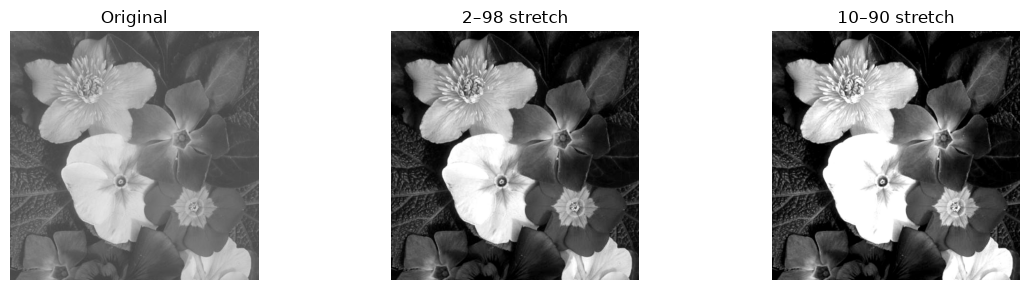

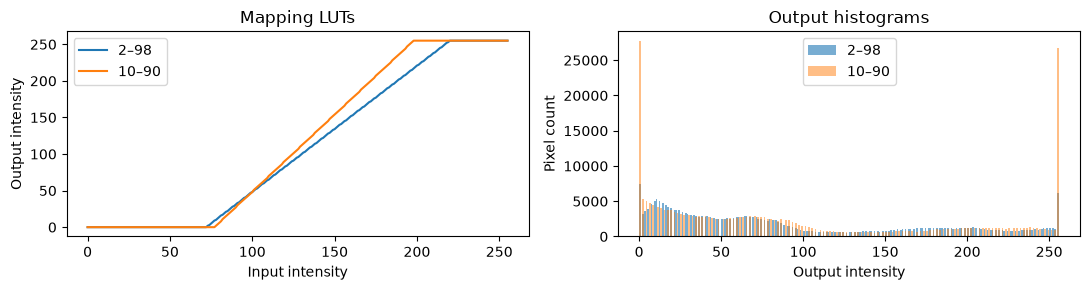

xray: 2–98 levels=(np.int64(28), np.int64(255)); 10–90 levels=(np.int64(68), np.int64(255))
Entropy — Original: 6.305, 2–98: 6.284, 10–90: 5.919


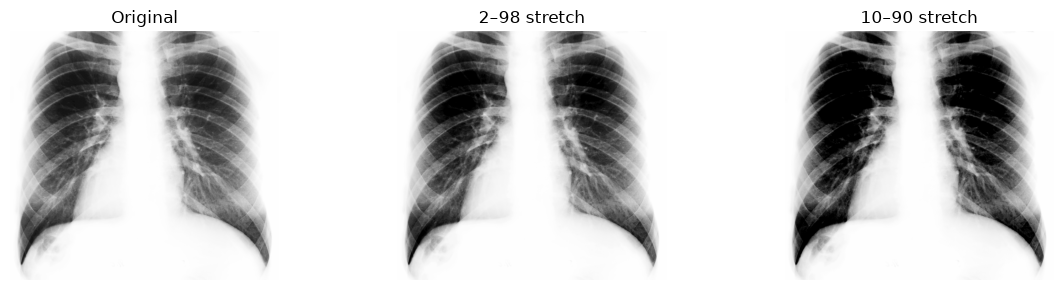

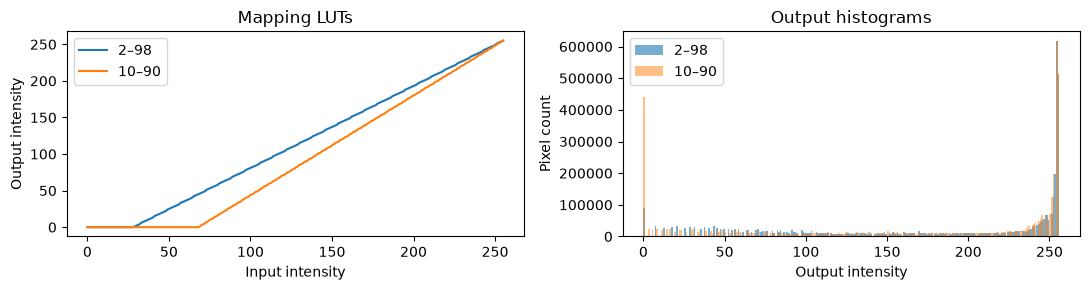

In [30]:
for name in ('flowers', 'xray'):
    img = images_q1[name]
    out_2, lut_2, levels_2 = percentile_stretch(img, 2, 98)
    out_10, lut_10, levels_10 = percentile_stretch(img, 10, 90)

    print(f"{name}: 2–98 levels={levels_2}; 10–90 levels={levels_10}")
    entropy_original = hist_stats(img)[-1]
    entropy_2 = hist_stats(out_2)[-1]
    entropy_10 = hist_stats(out_10)[-1]
    print(f"Entropy — Original: {entropy_original:.3f}, "
          f"2–98: {entropy_2:.3f}, 10–90: {entropy_10:.3f}")
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    for ax, (title, arr) in zip(axes, [
        ('Original', img), ('2–98 stretch', out_2), ('10–90 stretch', out_10)]):
        ax.imshow(arr, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title); ax.axis('off')
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    axes[0].plot(np.arange(256), lut_2, label='2–98')
    axes[0].plot(np.arange(256), lut_10, label='10–90')
    axes[0].set(xlabel='Input intensity', ylabel='Output intensity', title='Mapping LUTs')
    axes[0].legend()
    axes[1].hist(out_2.ravel(), bins=256, range=(0,256), alpha=.6, label='2–98')
    axes[1].hist(out_10.ravel(), bins=256, range=(0,256), alpha=.5, label='10–90')
    axes[1].set(xlabel='Output intensity', ylabel='Pixel count', title='Output histograms')
    axes[1].legend()
    plt.tight_layout(); plt.show()

<font color='red'><b>Answer the following questions:</b>

1. Which percentile range produced a better-looking image? Explain using the images and the mapping functions. Was any detail lost?

2. How did the entropy change after contrast stretching? Does a higher entropy always mean a better-looking image?

</font>

<span style="color:red">
<u>ANSWERS</u>

1. Better-looking is subjective. In our opinion, (2,98) produced a better-looking image.

   Pixel values were clipped in the (10,90) range, as everything below 10% was mapped to 0 (white), and everything above 90% was mapped to 255 (black). Some of the ribs and details of the white flower disappeared.

2. The entropy decreased. 
   Clipping causes more pixels to share the same bins (0 and 255), reducing uncertainty. Better-looking is subjective, and in our opinion, the answer is no.



</span>


### Histogram Mapping - The Two-Pointer Algorithm

So far, we have chosen the mapping ourselves. Now suppose we want the histogram of one image (the **source**) to resemble the histogram of another image (the **reference**). This is called **Histogram Matching**.

We can do this using the two images' CDFs, $F_s$ and $F_r$. For each source intensity $k$, we find the **first** reference intensity $j$ whose cumulative probability is at least as large:

$$
F_r(j) \geq F_s(k).
$$

As we saw in the tutorial, we can build this mapping with a **two-pointer algorithm**. One pointer moves through the source intensities, while the other moves forward through the reference intensities until the required CDF value is reached. **Neither pointer moves backward.**

In the next cell, implement:

**`two_pointer_lut(source_cdf, reference_cdf)`** - construct the 256-entry lookup table using the two-pointer algorithm.

**`histogram_match(source, reference)`** - calculate both CDFs, construct the LUT, and apply it to the source image.

**Important:** Implement the two-pointer algorithm yourself. Do not use `np.searchsorted`, `np.interp`, a histogram-matching library, or repeated searches from the beginning. All pixels with the same original intensity must be mapped to the same output intensity.


In [31]:
def two_pointer_lut(source_cdf: np.ndarray,
                    reference_cdf: np.ndarray) -> np.ndarray:
    """Return a monotone uint8 LUT of length 256 using TWO advancing pointers."""
    # TODO: walk through both CDFs without restarting the reference pointer
    source_pointer, dest_pointer = 0, 0
    lut = np.zeros(256, dtype=np.uint8)
  
    while (source_pointer < 256):
        if (dest_pointer >= 255 or source_cdf[source_pointer] <= reference_cdf[dest_pointer]):
            lut[source_pointer] = dest_pointer
            source_pointer += 1
        else:
            dest_pointer += 1

    return lut


def histogram_match(source: np.ndarray, reference: np.ndarray):
    """Return (mapped_image, LUT) using hist_stats and two_pointer_lut."""
    # TODO: compute the source/reference CDFs, then apply your LUT
    _, source_cdf, _, _, _ = hist_stats(source)
    _, reference_cdf, _, _, _ = hist_stats(reference)
    lut = two_pointer_lut(source_cdf,reference_cdf)
    mapped_image = lut[source]
    return (mapped_image,lut)


Let's start with a simple example before moving to real images.

Suppose the source has counts `[1, 1, 2]` and the reference has counts `[2, 1, 1]` at intensity levels `0, 1, 2` (all other counts are zero). First, predict where source intensities `0`, `1`, and `2` will be mapped. Then run the next cell to check your answer.


In [32]:
toy_source = np.array([[0, 1, 2, 2]], dtype=np.uint8)
toy_reference = np.array([[0, 0, 1, 2]], dtype=np.uint8)
toy_mapped, toy_lut = histogram_match(toy_source, toy_reference)
print("Mapping [0, 1, 2] ->", toy_lut[:3].tolist())
print("Mapped pixels:", toy_mapped.ravel().tolist())
assert toy_lut[:3].tolist() == [0, 0, 2]
assert np.all(np.diff(toy_lut.astype(np.int16)) >= 0)

Mapping [0, 1, 2] -> [0, 0, 2]
Mapped pixels: [0, 0, 2, 2]


Now, apply Histogram Matching to two images from the dataset: use **flowers** as the source and **building** as the reference.

Run the following cell to compare the source, reference, and transformed images, together with their histograms and your mapping function.


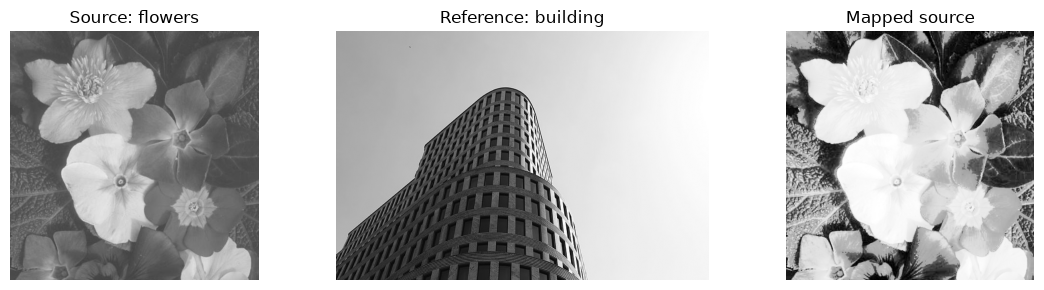

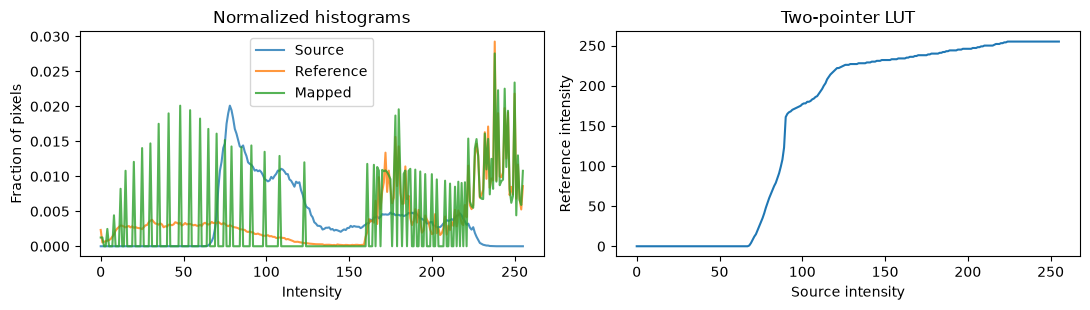

In [33]:
source = images_q1['flowers']
reference = images_q1['building']
mapped, match_lut = histogram_match(source, reference)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, img) in zip(axes, [
    ('Source: flowers', source), ('Reference: building', reference),
    ('Mapped source', mapped)]):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for name, img in [('Source', source), ('Reference', reference), ('Mapped', mapped)]:
    axes[0].plot(np.arange(256), histogram(img) / img.size, alpha=.8, label=name)
axes[0].set(xlabel='Intensity', ylabel='Fraction of pixels', title='Normalized histograms')
axes[0].legend()
axes[1].plot(np.arange(256), match_lut)
axes[1].set(xlabel='Source intensity', ylabel='Reference intensity', title='Two-pointer LUT')
plt.tight_layout(); plt.show()

Now, let's compare this with matching to a <b>uniform histogram</b>. A uniform histogram assigns the same probability, $1/256$, to every gray level. This time, we do not need a reference image: we can construct the target CDF directly.

Use your `two_pointer_lut` function to match the <b>flowers</b> image to the uniform target. Display the resulting image and compare its histogram with the image matched to <b>building</b>.

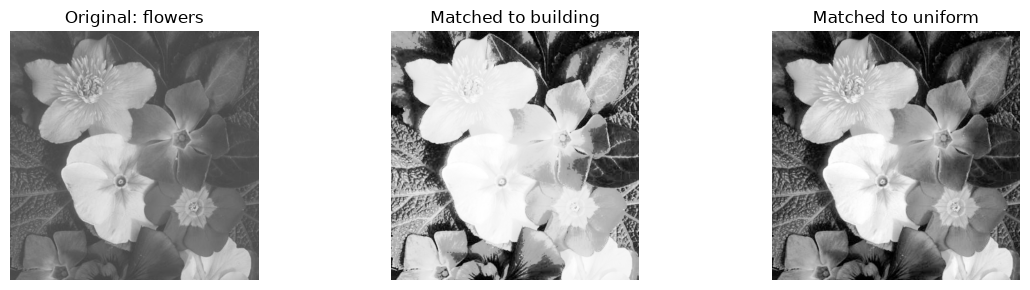

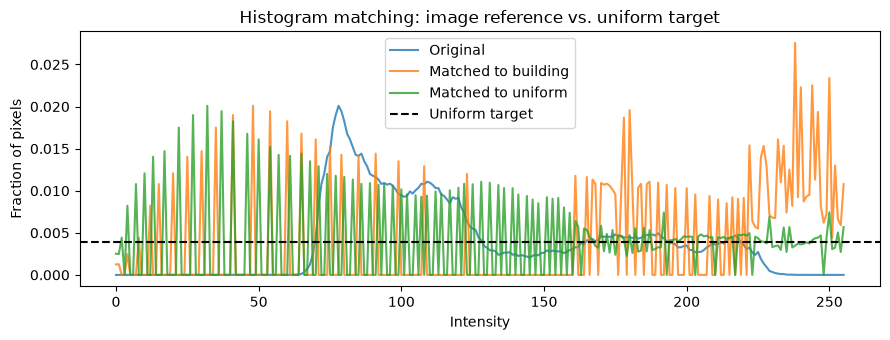

In [34]:
# A uniform histogram has probability 1/256 for each gray level.
uniform_cdf = np.cumsum(np.ones(256) / 256)
source_cdf = hist_stats(source)[1]

# TODO: use two_pointer_lut to construct a LUT for the uniform target
lut = two_pointer_lut(source_cdf, uniform_cdf)
# TODO: apply this LUT to the flowers image and store it as uniform_mapped
uniform_mapped = lut[source]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, img) in zip(axes, [
    ('Original: flowers', source),
    ('Matched to building', mapped),
    ('Matched to uniform', uniform_mapped)]):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 3.5))
for name, img in [('Original', source), ('Matched to building', mapped),
                  ('Matched to uniform', uniform_mapped)]:
    plt.plot(np.arange(256), histogram(img) / img.size, label=name, alpha=.8)
plt.axhline(1/256, color='black', linestyle='--', label='Uniform target')
plt.xlabel('Intensity'); plt.ylabel('Fraction of pixels')
plt.title('Histogram matching: image reference vs. uniform target')
plt.legend(); plt.tight_layout(); plt.show()

<font color='red'><b>Answer the following questions:</b>

1. In the simple example, why did source intensities 0 and 1 both map to intensity 0?

2. Does the mapped image always have exactly the same histogram as the reference image? Explain why or why not, considering that pixels of the same input intensity must be mapped together.

3. How did the result change when matching to a uniform histogram instead of the building image? Why might the resulting histogram still not be perfectly uniform?

</font>

<span style="color:red">
<u>ANSWERS:</u>

1. cdf_source [1,2,4]; cdf_dest [2,3,4]. Following the two-pointer algorithm, intensities 0 and 1 of the source fit into bin 0 of the destination.

2. No, this algorithm doesn't split histogram bins. It can only distribute them differently or combine bins.

3. The contrast and entropy increased, which subjectively resulted in a better-looking image. The histogram is not uniform because histogram bins cannot be split. The algorithm doesn't specify a mapping that divides a specific intensity into different bins. Each input intensity is mapped to one output intensity.

</span>


### Can We Estimate Focus from a Histogram?

When an image becomes blurry, it loses fine details. In this section, we will test a simple idea: **Can the intensity standard deviation, which measures contrast, tell us how blurry an image is?**

We provide a Gaussian blur function for you. **You do not need to implement the blur.**

Apply it to the **flowers** image using the blur strengths in the next cell. For each result, calculate the standard deviation using your `hist_stats` function and plot **blur strength versus standard deviation**. Display the images for `sigma = 0, 3, 10`.

Finally, apply your `percentile_stretch` function to the most blurred image. Compare its contrast and visual sharpness with the original image.


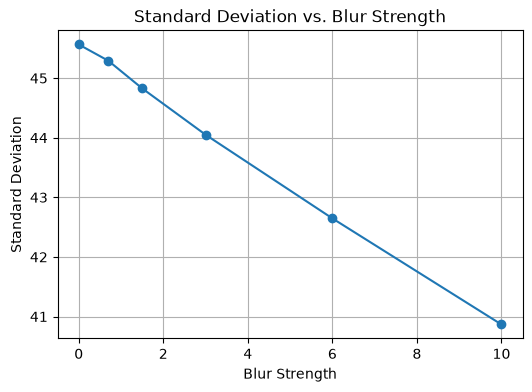

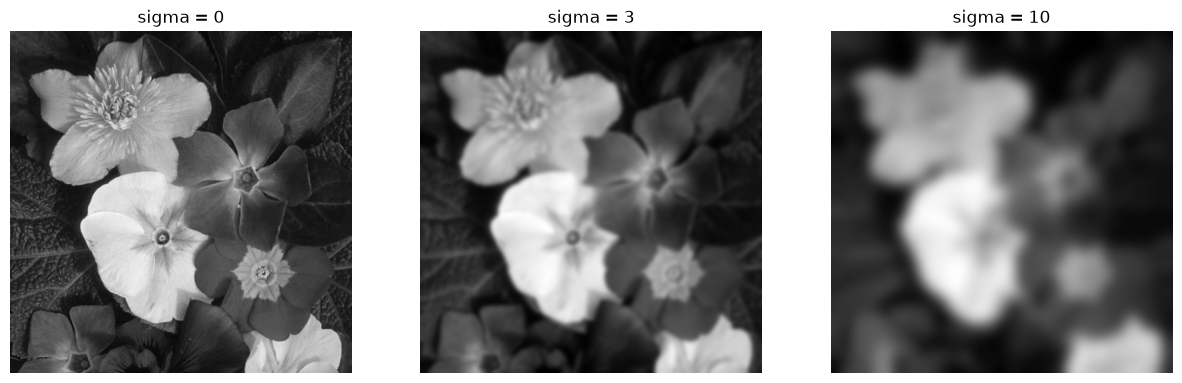

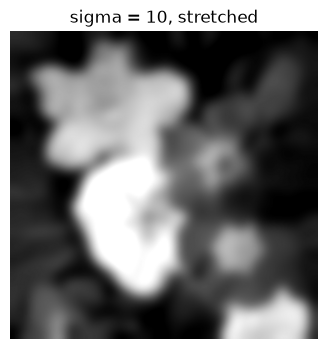

std sigma=0: 45.564507104954124  std sigma=10: 40.86645252851861  std stretched: 80.00280686498138


In [35]:
def supplied_gaussian_blur(img: np.ndarray, sigma: float) -> np.ndarray:
    """Provided Gaussian blur with reflect-101 boundaries."""
    if sigma == 0:
        return img.copy()
    return cv.GaussianBlur(img, (0, 0), sigmaX=sigma,
                           borderType=cv.BORDER_REFLECT_101)


sigmas = [0, 0.7, 1.5, 3, 6, 10]
blurred_images = [supplied_gaussian_blur(images_q1['flowers'], s) for s in sigmas]

# TODO: use hist_stats to calculate standard deviation for every blurred image
stds = [hist_stats(img)[3] for img in blurred_images]

# TODO: plot blur strength (x-axis) versus intensity standard deviation (y-axis)
plt.plot(sigmas, stds, marker='o')
plt.xlabel("Blur Strength")
plt.ylabel("Standard Deviation")
plt.title("Standard Deviation vs. Blur Strength")
plt.grid(True)

# TODO: display the images for sigma=0, sigma=3, and sigma=10
target_sigmas = [0, 3, 10]
indices = [sigmas.index(s) for s in target_sigmas]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, i in zip(axes, indices):
    ax.imshow(blurred_images[i], cmap='gray')
    ax.set_title(f"sigma = {sigmas[i]}")
    ax.axis('off')
plt.show() 

# TODO: stretch the most blurred image using percentile_stretch,
#       display it, and compare the three standard deviations
stretched_img, _, _ = percentile_stretch(blurred_images[5])
plt.figure()                    
plt.imshow(stretched_img, cmap='gray')
plt.title("sigma = 10, stretched")
plt.axis('off')
plt.show()

print("std sigma=0:", stds[0], " std sigma=10:", stds[5], " std stretched:", hist_stats(stretched_img)[3])


<font color='red'><b>Answer the following questions:</b>

1. What happened to the standard deviation as the blur increased? Does this agree with what you see in the images?

2. After stretching the contrast of the blurred image, did the missing details return? Explain why increasing contrast is not necessarily the same as improving focus.

</font>

<span style="color:red">
<u>ANSWERS:</u>

1. The standard deviation decreased, which explains the lower visible contrast.
2. No, the missing details were lost during the blurring process. stretching increases the spread/range of pixel values (up to clipping), so the differences in intensity between pixels increase, resulting in higher contrast. However, it doesn't restore the lost information.
</span>


## Question 2 - Finding an Optimal Threshold (40 Points)

In this question, we will study **automatic thresholding** - a simple way to separate an object from its background using pixel intensities.

For a grayscale image, we choose a threshold $T$. Pixels with intensity greater than $T$ become **foreground** (white), while the rest become **background** (black). The main challenge is deciding which threshold to use.

We will first try a fixed threshold, then implement two methods that choose one automatically, and finally compare them on clean, noisy, and unevenly illuminated images.

The provided images contain the same object under different conditions. We also provide a ground-truth mask so you can check how well your segmentation works.


### Choosing a Threshold

Let's start with a fixed threshold of `T = 127`.

Run the next cell, which applies this threshold to the three images and shows their histograms. The provided `binary_segment` function performs the thresholding, while `mask_iou` compares the result against the ground-truth mask using **Intersection over Union (IoU)**. An IoU of 1 means perfect agreement.


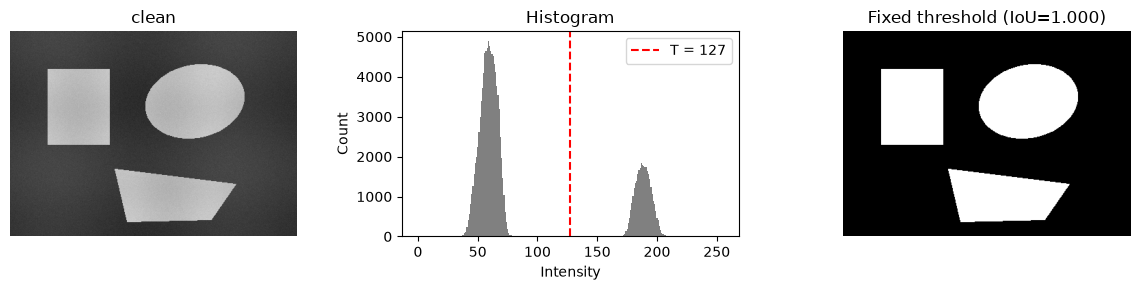

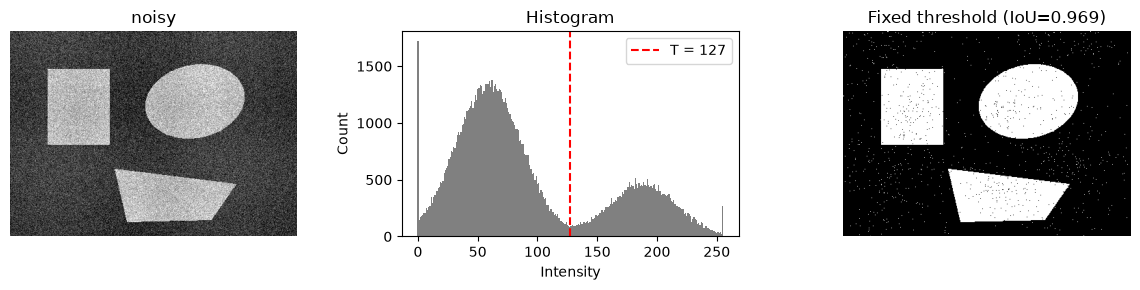

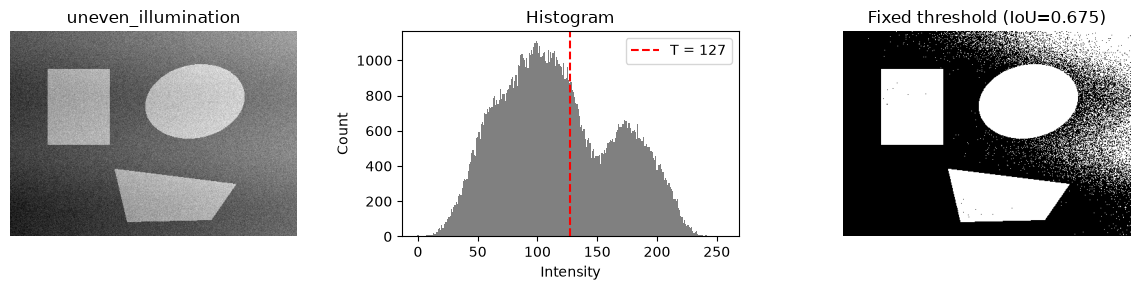

In [36]:
def binary_segment(img: np.ndarray, threshold: float) -> np.ndarray:
    """Provided helper: 255 = foreground; 0 = background."""
    return np.where(img > threshold, 255, 0).astype(np.uint8)


def mask_iou(prediction: np.ndarray, truth: np.ndarray) -> float:
    """Provided Intersection over Union (IoU) for foreground masks."""
    a, b = prediction > 0, truth > 0
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 1.0


images_q2 = {
    name: imread_gray(os.path.join(data_root_q2, f'{name}.png'))
    for name in ('clean', 'noisy', 'uneven_illumination')
}
truth = imread_gray(os.path.join(data_root_q2, 'ground_truth.png'))

for name, img in images_q2.items():
    hist, _, _, _, _ = hist_stats(img)
    fixed = binary_segment(img, 127)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(name); axes[0].axis('off')
    axes[1].bar(np.arange(256), hist, color='gray', width=1)
    axes[1].axvline(127, color='red', linestyle='--', label='T = 127')
    axes[1].set(xlabel='Intensity', ylabel='Count', title='Histogram')
    axes[1].legend()
    axes[2].imshow(fixed, cmap='gray', vmin=0, vmax=255)
    axes[2].set_title(f'Fixed threshold (IoU={mask_iou(fixed, truth):.3f})')
    axes[2].axis('off')
    plt.tight_layout(); plt.show()

<font color='red'><b>Answer the following questions:</b>

1. On which image did the fixed threshold work best? Use the results and histograms to explain why.

2. Why might the same threshold fail when the lighting changes?

</font>

<span style="color:red">Your answer here.</span>


### Iterative Optimal Thresholding

Instead of selecting a fixed threshold ourselves, we can estimate it from the image. A simple idea is that a good threshold should lie between the average intensity of the background and the average intensity of the object.

The **iterative optimal thresholding** algorithm works as follows:

- Start with an initial threshold $T$.
- Divide the pixels into two groups: intensities $\leq T$ and intensities $>T$.
- Calculate the mean intensity of each group, $\mu_0$ and $\mu_1$.
- Update the threshold using the average of these two means:

$$
T_{\mathrm{new}}=\frac{\mu_0+\mu_1}{2}.
$$

Repeat the process until the threshold changes by less than `tol`, or until `max_iter` iterations have been reached. If one of the groups is empty, stop and keep the last valid threshold.

In the next cell, implement `iterative_threshold`. Return the final threshold and a list of all threshold values, including the initial one. Do not use a built-in automatic thresholding function.


In [37]:
def iterative_threshold(img: np.ndarray, initial: float = 127.5,
                        tol: float = 0.5, max_iter: int = 100):
    """Return (final_threshold, history), with the initial value in history."""
    # TODO: repeatedly split into <=T and >T, recompute class means,
    #       and update T until convergence
    raise NotImplementedError

Now, let's see how the initial threshold affects the result.

Run your implementation on the **noisy** image with initial thresholds `60`, `127.5`, and `200`. Use the next cell to plot the threshold at every iteration and compare the final threshold and segmentation accuracy for each run.


In [38]:
noisy = images_q2['noisy']
plt.figure(figsize=(7, 3.8))
for initial in (60, 127.5, 200):
    T, history = iterative_threshold(noisy, initial=initial)
    seg = binary_segment(noisy, T)
    print(f"Initial={initial:5.1f} -> final={T:7.3f}, "
          f"iterations={len(history)-1}, IoU={mask_iou(seg, truth):.3f}")
    plt.plot(range(len(history)), history, marker='o', label=f'initial={initial}')
plt.xlabel('Iteration'); plt.ylabel('Threshold value')
plt.title('Iterative threshold convergence — noisy image')
plt.legend(); plt.tight_layout(); plt.show()

NotImplementedError: 

<Figure size 700x380 with 0 Axes>

<font color='red'><b>Answer the following questions:</b>

1. Did the three initial thresholds lead to the same final threshold? Explain what you observed.

2. If the algorithm has converged, does that necessarily mean it separated the object correctly? Why?

</font>

<span style="color:red">Your answer here.</span>


### Otsu's Method

The previous method updates a threshold until it stops changing. We will now try another approach, called **Otsu's method**, which chooses a threshold by looking at the histogram.

The idea is simple: if an image contains a dark background and a bright object, we would like to split its intensities into **two groups with as little variation inside each group as possible**.

For each candidate threshold $t$:

- Divide the histogram into two groups: intensities $\leq t$ and intensities $>t$.
- Calculate the fraction of pixels in each group, $w_0$ and $w_1$.
- Calculate the variance of the intensities inside each group, $\sigma_0^2$ and $\sigma_1^2$.

We measure the quality of the split using the **weighted within-class variance**:

$$
J(t)=w_0\sigma_0^2+w_1\sigma_1^2.
$$

The smaller $J(t)$ is, the more similar the intensities are within the two groups. **Otsu's method chooses the threshold that minimizes this value.** You can calculate each group's mean and variance from its part of the histogram, just as you calculated statistics for the whole image in Question 1.

In the next cell, implement `otsu_threshold` by testing thresholds from 0 to 254. Return the best threshold and the 255 values of $J(t)$. If a threshold leaves one group empty, give it a score of `np.inf`. If several thresholds have the same minimum score, choose the smallest. If no split is possible, return 0.

Do not use OpenCV's automatic thresholding function in your implementation. We will use it only later to check the result.


In [ ]:
def otsu_threshold(img: np.ndarray):
    """Return (best_integer_threshold, J_scores), with 255 candidate scores."""
    # TODO: use the normalized histogram to evaluate J(t), t=0,...,254
    # TODO: assign np.inf to invalid splits; choose the first minimum
    raise NotImplementedError

Let's validate your implementation.

Run your method on the **noisy** image and use the next cell to plot $J(t)$ for the possible thresholds. Check where the minimum occurs and compare your selected threshold with OpenCV's implementation of Otsu's method.


In [ ]:
T_otsu, scores = otsu_threshold(images_q2['noisy'])
T_cv, _ = cv.threshold(images_q2['noisy'], 0, 255,
                       cv.THRESH_BINARY + cv.THRESH_OTSU)
print(f"Your Otsu threshold: {T_otsu}; OpenCV Otsu threshold: {T_cv:g}")
assert scores.shape == (255,)
plt.figure(figsize=(8, 3.5))
plt.plot(np.arange(255), scores, label='Weighted within-class variance')
plt.axvline(T_otsu, color='red', linestyle='--', label=f'Minimum: {T_otsu}')
plt.xlabel('Candidate threshold'); plt.ylabel('J(t)')
plt.title('Otsu objective — noisy image')
plt.legend(); plt.tight_layout(); plt.show()

<font color='red'><b>Answer the following questions:</b>

1. Why is it reasonable to look for two groups with low variance when separating an object from its background?

2. Does the threshold that minimizes $J(t)$ always give the most accurate segmentation? Explain.

</font>

<span style="color:red">Your answer here.</span>


### Comparing the Methods

Now, let's put both automatic thresholding methods to the test on the three images.

For each image, use your two implementations to select a threshold and generate a binary segmentation. Print the selected thresholds and their IoU scores, then display the original image, both segmentations, and the ground-truth mask side by side.

Use the same rule throughout the question: pixels **greater than the threshold** are foreground. The `mask_iou` helper has already been implemented for you.


In [ ]:
for name, img in images_q2.items():
    # TODO: run iterative_threshold and otsu_threshold on img
    # TODO: obtain binary predictions for both methods
    # TODO: print each selected threshold and IoU against truth
    # TODO: display input, iterative output, Otsu output and ground truth
    pass

<font color='red'><b>Answer the following questions:</b>

1. Which method worked better on each image? Explain using the results.

2. Which image was most difficult to segment? What can we learn about the limitations of selecting a single threshold using only the histogram?

</font>

<span style="color:red">Your answer here.</span>
